# Phase 1, Part B: Denoisers and Metrics

Run this notebook top to bottom (**Kernel → Restart & Run All**) from the `notebooks/` folder.
It checks every Part B Phase 1 deliverable on the **real Set12** images:

1. Part A's loader and AWGN generator feed Part B's denoisers (the hand-off works).
2. The metrics (PSNR, SSIM, method noise, timing) behave as theory says.
3. Mean, Gaussian, median and Wiener filters denoise visibly and measurably.
4. The preliminary sanity-check table (all of Set12, σ = 15/25/50) and its plots.
5. Two previews of Phase 2 questions: parameter sensitivity, and what happens when the Wiener filter is told the **wrong** σ.

Pass/fail checks are `assert`s, so a red cell means something is wrong.

In [1]:
import subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repo root (the folder with pytest.ini) so imports work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pytest.ini").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.config import load_config
from utils.data_loader import load_dataset
from utils.seed import make_rng
from noise import add_awgn                                   # Part A
from denoisers import denoise, PHASE1_METHODS                # Part B
from metrics import psnr, ssim, method_noise, timed          # Part B
from analysis.sanity_check import run_sanity, summarize, check_sanity, sanity_params

cfg = load_config()
SEED = cfg["seed"]
SIGMAS_255 = cfg["noise"]["awgn"]["sigmas_255"]

# One fixed colour per method, used in every plot (colour follows the method, not its rank).
COLORS = {"noisy": "#7f7f7f", "mean": "#0072B2", "gaussian": "#009E73",
          "median": "#E69F00", "wiener": "#CC79A7"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 10,
                     "axes.labelsize": 9, "legend.frameon": False, "image.cmap": "gray"})
print("repo root:", ROOT, "| seed:", SEED, "| sigmas (x/255):", SIGMAS_255)

/home/kiranr/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


repo root: /home/kiranr/Documents/4-1/DIP/project/denoising-mismatch | seed: 2026 | sigmas (x/255): [15, 25, 50]


## 1. Load the real Set12 (Part A loader)

12 images: ['01.png', '02.png', '03.png', '04.png', '05.png', '06.png', '07.png', '08.png', '09.png', '10.png', '11.png', '12.png']


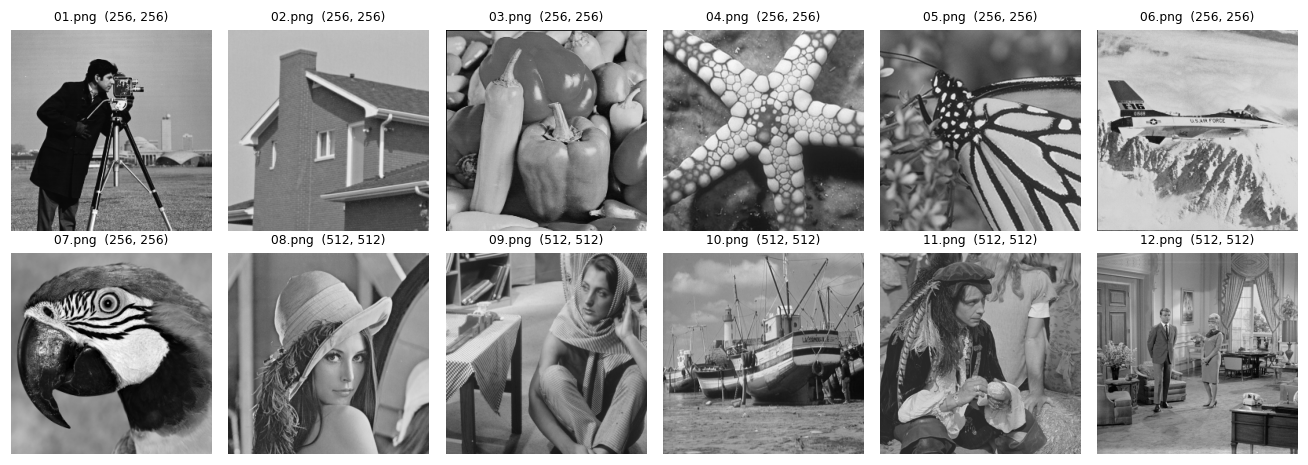

In [2]:
images = load_dataset("set12", data_root=ROOT / cfg["data_root"])
print(f"{len(images)} images:", [n for n, _ in images])
assert len(images) == 12, "Set12 should have 12 images"
for n, a in images:
    assert a.ndim == 2 and a.dtype == np.float64 and 0.0 <= a.min() and a.max() <= 1.0, n

fig, axes = plt.subplots(2, 6, figsize=(12, 4.3))
for ax, (n, a) in zip(axes.ravel(), images):
    ax.imshow(a, vmin=0, vmax=1); ax.set_title(f"{n}  {a.shape}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Metric sanity checks

For AWGN with std $\sigma$ (images in $[0,1]$), the noisy image has $\mathrm{MSE}\approx\sigma^2$, so

$$\mathrm{PSNR}_\text{noisy}\approx 10\log_{10}\frac{1}{\sigma^2}=-20\log_{10}\sigma .$$

For $\sigma=25/255$ this is about 20.17 dB. If our PSNR on a real noisy image matches, then the noise generator
(Part A), the metric (Part B) and the unit convention ($\sigma/255$) all agree.

In [3]:
IMG_IDX = 0                      # change this to look at another Set12 image
name, x = images[IMG_IDX]
sigma255 = 25
sigma = sigma255 / 255
z = add_awgn(x, sigma, make_rng(SEED, name, sigma255, "notebook"), clip=cfg.get("clip_noisy", False))

print(f"image: {name}")
print(f"empirical noise mean = {(z - x).mean():+.5f} (expect ~0), std = {(z - x).std():.5f} (expect {sigma:.5f})")
theory = -20 * np.log10(sigma)
print(f"PSNR(noisy) = {psnr(x, z):.2f} dB, theory = {theory:.2f} dB")
assert abs(psnr(x, z) - theory) < 0.1

assert psnr(x, x) == np.inf and abs(ssim(x, x) - 1) < 1e-12
assert abs(psnr(np.zeros((8, 8)), np.full((8, 8), 0.1)) - 20.0) < 1e-9     # MSE 0.01 -> 20 dB
print("metric checks passed")

image: 01.png
empirical noise mean = -0.00027 (expect ~0), std = 0.09817 (expect 0.09804)
PSNR(noisy) = 20.16 dB, theory = 20.17 dB
metric checks passed


## 3. The four denoisers on one image (σ = 25/255)

In [4]:
out, rows = {}, []
for m in PHASE1_METHODS:
    params = sanity_params(m, sigma)             # wiener is told the TRUE sigma here (matched case)
    x_hat, dt = timed(denoise, m, z, params)
    out[m] = x_hat
    rows.append(dict(method=m, params=params or "defaults", psnr=psnr(x, x_hat), ssim=ssim(x, x_hat), ms=1000 * dt))
rows.insert(0, dict(method="noisy", params="-", psnr=psnr(x, z), ssim=ssim(x, z), ms=0.0))
pd.DataFrame(rows).round(4)

,method,params,psnr,ssim,ms
0,noisy,-,20.1602,0.3494,0.0000
1,mean,defaults,24.4531,0.5928,1.3222
2,gaussian,defaults,24.8832,0.6503,0.9761
3,median,defaults,24.3673,0.5418,8.2083
4,wiener,"{'size': 3, 'noise_sigma': 0.09803921568627451}",25.9274,0.5892,5.8487


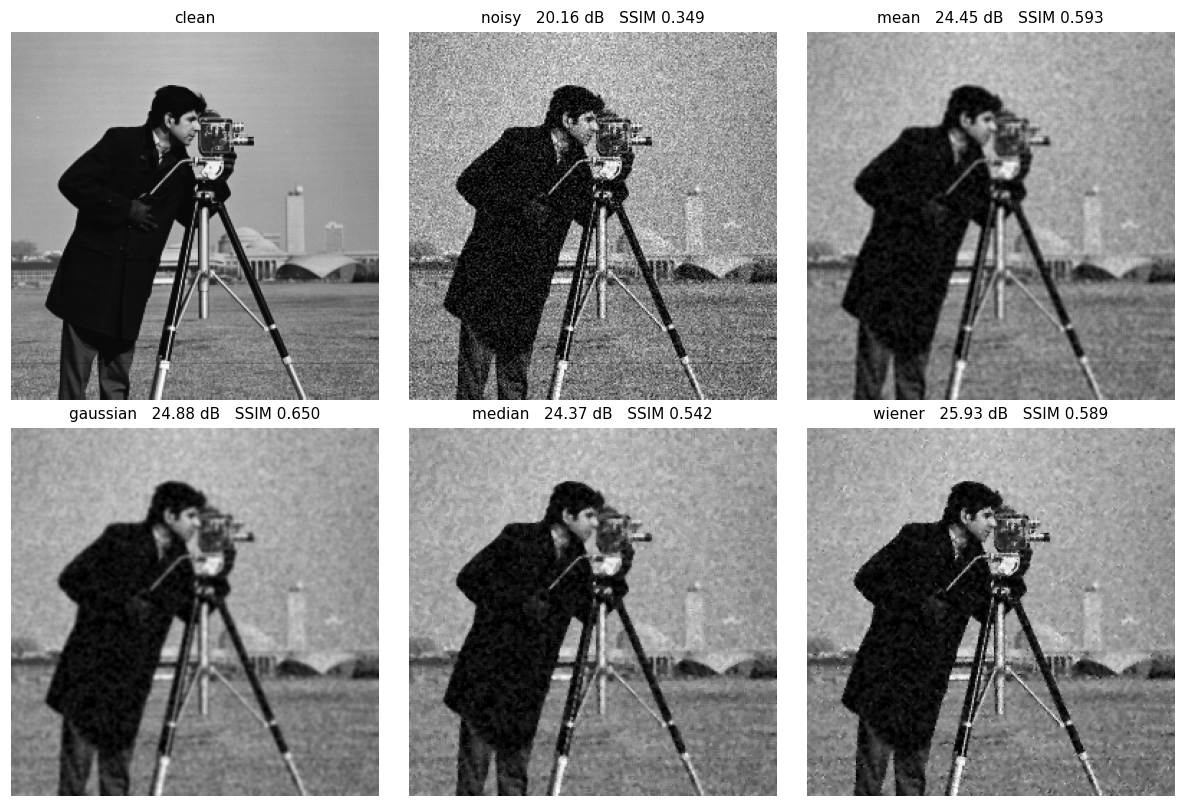

In [5]:
panels = [("clean", x, None), ("noisy", z, None)] + [(m, out[m], m) for m in PHASE1_METHODS]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (title, img, m) in zip(axes.ravel(), panels):
    ax.imshow(np.clip(img, 0, 1), vmin=0, vmax=1); ax.axis("off")
    ax.set_title(title if title == "clean" else f"{title}   {psnr(x, img):.2f} dB   SSIM {ssim(x, img):.3f}")
plt.tight_layout(); plt.show()

## 4. Method noise (what each filter removed)

Method noise is $z-\hat x$. A good denoiser removes mostly noise, so the residual should look like noise with
**no visible image structure**; edges in it mean the filter removed signal. This is an informal preview; the proper
energy/structure statistics are Phase 2. Column `edge_corr` is the correlation between $|z-\hat x|$ and the clean
image's gradient magnitude (higher = the residual contains more edge content).

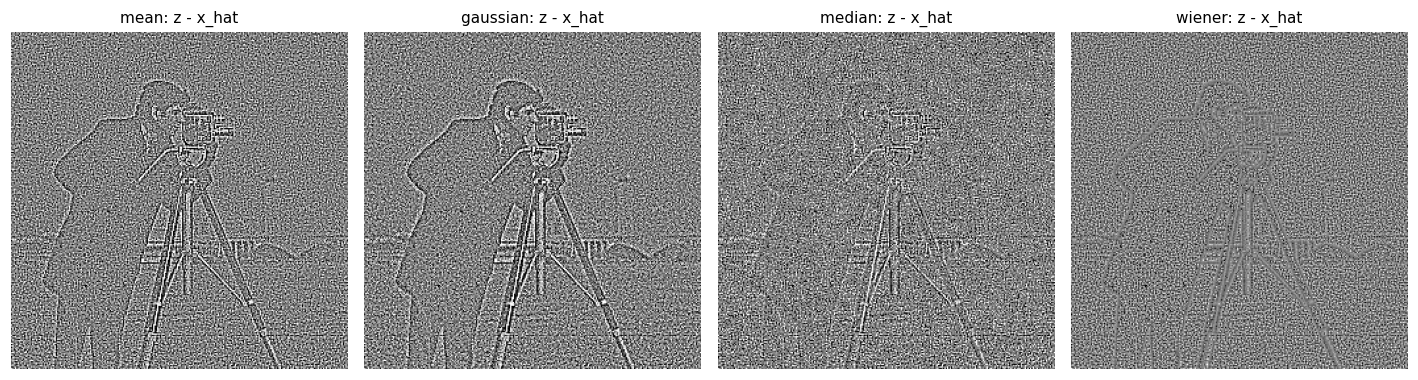

,method,mean,std,std_over_sigma,edge_corr
0,mean,-0.0002,0.1048,1.0692,0.2410
1,gaussian,-0.0001,0.0986,1.0053,0.2556
2,median,0.0005,0.1044,1.0653,0.0708
3,wiener,-0.0007,0.0776,0.7911,-0.2140


In [6]:
grad = np.hypot(*np.gradient(x))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
stats = []
for ax, m in zip(axes, PHASE1_METHODS):
    r = method_noise(z, out[m])
    ax.imshow(r, vmin=-0.2, vmax=0.2); ax.axis("off"); ax.set_title(f"{m}: z - x_hat")
    stats.append(dict(method=m, mean=r.mean(), std=r.std(), std_over_sigma=r.std() / sigma,
                      edge_corr=np.corrcoef(np.abs(r).ravel(), grad.ravel())[0, 1]))
plt.tight_layout(); plt.show()
pd.DataFrame(stats).round(4)

## 5. The preliminary sanity-check table (all of Set12, AWGN σ = 15/25/50)

In [7]:
df = run_sanity(images, SIGMAS_255, SEED, cfg.get("clip_noisy", False))
summary = summarize(df)
warn = check_sanity(summary)
print("sanity warnings:", warn or "none (every method beats the noisy input at every sigma)")
assert not warn
summary.round(4)

sanity warnings: none (every method beats the noisy input at every sigma)


,sigma_255,method,psnr,ssim,time_ms,n_images
0,15,noisy,24.6137,0.5598,0.0000,12
1,15,mean,27.5235,0.7794,1.8711,12
2,15,gaussian,27.6741,0.8080,2.6650,12
3,15,median,27.8045,0.7465,17.9600,12
4,15,wiener,29.5245,0.7891,10.8424,12
5,25,noisy,20.1723,0.3898,0.0000,12
6,25,mean,26.0272,0.6683,2.0323,12
7,25,gaussian,26.5057,0.7161,2.6775,12
8,25,median,25.4519,0.6115,18.1608,12
9,25,wiener,26.1589,0.6465,11.4280,12


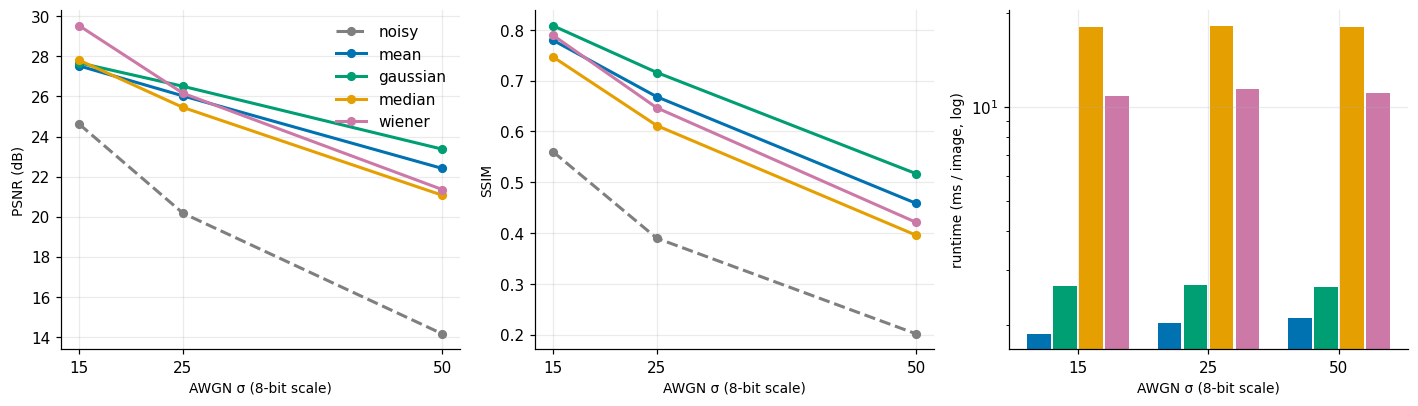

In [8]:
S = summary.assign(method=summary["method"].astype(str))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, label in [(axes[0], "psnr", "PSNR (dB)"), (axes[1], "ssim", "SSIM")]:
    piv = S.pivot(index="sigma_255", columns="method", values=col)
    for m in ["noisy", *PHASE1_METHODS]:
        ax.plot(piv.index, piv[m], marker="o", ms=5, lw=2, color=COLORS[m],
                ls="--" if m == "noisy" else "-", label=m)
    ax.set_xlabel("AWGN σ (8-bit scale)"); ax.set_ylabel(label); ax.set_xticks(piv.index)
axes[0].legend(loc="upper right")
t = S[S.method != "noisy"].pivot(index="sigma_255", columns="method", values="time_ms")[list(PHASE1_METHODS)]
w = 0.2
for i, m in enumerate(PHASE1_METHODS):
    axes[2].bar(np.arange(len(t)) + (i - 1.5) * w, t[m], w * 0.9, color=COLORS[m], label=m)
axes[2].set_xticks(range(len(t))); axes[2].set_xticklabels(t.index); axes[2].set_yscale("log")
axes[2].set_xlabel("AWGN σ (8-bit scale)"); axes[2].set_ylabel("runtime (ms / image, log)")
plt.tight_layout(); plt.show()

## 6. Preview of Phase 2: how sensitive is each method to its parameters?

The defaults (3×3 windows, `filter_sigma=1`) are **not tuned**. This table, on the first 4 images at σ = 25/255,
shows how much PSNR depends on the window size or kernel width. It is why Phase 2 needs a documented
parameter policy. (Wiener is given the true σ here.)

In [9]:
subset = images[:4]
noisy_subset = [(n, a, add_awgn(a, 25 / 255, make_rng(SEED, n, 25, "sens"))) for n, a in subset]

def avg_psnr(method, params):
    return float(np.mean([psnr(a, denoise(method, zz, params)) for _, a, zz in noisy_subset]))

sizes = [3, 5, 7, 9]
size_tbl = pd.DataFrame({
    "mean":   [avg_psnr("mean",   {"size": s}) for s in sizes],
    "median": [avg_psnr("median", {"size": s}) for s in sizes],
    "wiener": [avg_psnr("wiener", {"size": s, "noise_sigma": 25 / 255}) for s in sizes],
}, index=pd.Index(sizes, name="window size")).T
fsig = [0.5, 1.0, 1.5, 2.0, 3.0]
gauss_tbl = pd.DataFrame({"gaussian": [avg_psnr("gaussian", {"filter_sigma": s}) for s in fsig]},
                         index=pd.Index(fsig, name="filter_sigma (px)")).T
print("mean PSNR (dB), first 4 images, AWGN σ = 25/255")
print(size_tbl.round(2).to_string()); print(); print(gauss_tbl.round(2).to_string())

mean PSNR (dB), first 4 images, AWGN σ = 25/255
window size      3      5      7      9
mean         26.07  24.55  23.21  22.15
median       25.63  24.80  23.84  22.87
wiener       26.27  26.86  26.54  26.09

filter_sigma (px)    0.5    1.0    1.5    2.0   3.0
gaussian           23.91  26.55  25.29  24.07  22.3


## 7. Preview of the mismatch protocol: telling Wiener the wrong σ

The true noise is σ = 25/255, but the Wiener filter is told $\sigma_\text{assumed}$. When the assumed value is too
low it under-smooths (noise survives); too high and it over-smooths (detail lost). The dashed line is scipy's own
estimate (`noise_sigma=None`), which uses no knowledge of the noise at all. In Phase 2, "mismatched" runs decide
exactly which σ each method gets; this plot shows why that choice matters.

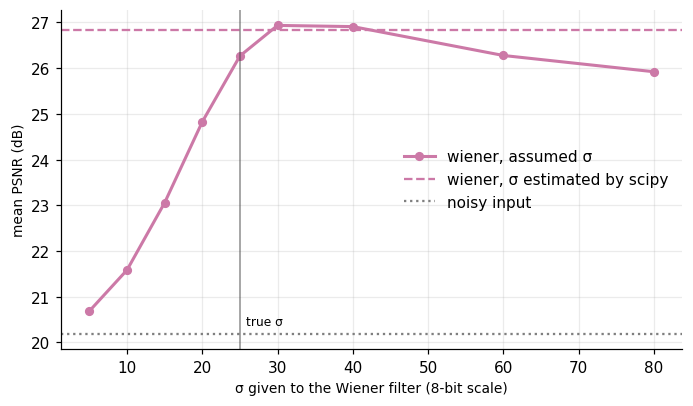

best assumed σ = 30/255 (true: 25/255); scipy-estimated: 26.83 dB


In [10]:
assumed = [5, 10, 15, 20, 25, 30, 40, 60, 80]
curve = [avg_psnr("wiener", {"size": 3, "noise_sigma": s / 255}) for s in assumed]
auto = avg_psnr("wiener", {"size": 3, "noise_sigma": None})
base = float(np.mean([psnr(a, zz) for _, a, zz in noisy_subset]))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(assumed, curve, marker="o", ms=5, lw=2, color=COLORS["wiener"], label="wiener, assumed σ")
ax.axhline(auto, color=COLORS["wiener"], ls="--", lw=1.5, label="wiener, σ estimated by scipy")
ax.axhline(base, color=COLORS["noisy"], ls=":", lw=1.5, label="noisy input")
ax.axvline(25, color="#444", lw=1, alpha=0.6); ax.text(25.8, base + 0.2, "true σ", fontsize=8)
ax.set_xlabel("σ given to the Wiener filter (8-bit scale)"); ax.set_ylabel("mean PSNR (dB)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"best assumed σ = {assumed[int(np.argmax(curve))]}/255 (true: 25/255); scipy-estimated: {auto:.2f} dB")

## 8. Run the unit and integration tests

In [11]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-500:])
assert r.returncode == 0, "some tests failed"

........................................................................ [ 60%]
...............................................                          [100%]
 


## Checklist: what to look for

- Section 2: empirical noise mean ≈ 0, std ≈ σ; PSNR(noisy) ≈ 20.17 dB. All asserts pass.
- Section 3/5: every method beats the noisy input (the sanity assertion); PSNR drops and runtime stays small as σ grows.
- Section 4: the residuals look like noise; `std_over_sigma` shows how much each filter removed relative to the noise level.
- Section 7: the Wiener curve peaks near the true σ and falls on both sides.
- Section 8: all tests pass, including the Set12 integration test (not skipped).

To save the table for the report, run `python -m analysis.sanity_check` (writes `results/phase1_sanity_*.csv|md`).